# Generative Art

Pictures from rules and randomness. A seeded random number generator makes
every run of a cell draw the same picture; change the seed for another.
Cells draw on a canvas and show it as an image, or build SVG as text.

## Seeded randomness

`Math.random()` can't be seeded. Mulberry32 is a small generator that can:
the same seed gives the same sequence.

In [1]:
function rng(seed: number) {
  return () => {
    seed |= 0;
    seed = (seed + 0x6d2b79f5) | 0;
    let t = Math.imul(seed ^ (seed >>> 15), 1 | seed);
    t = (t + Math.imul(t ^ (t >>> 7), 61 | t)) ^ t;
    return ((t ^ (t >>> 14)) >>> 0) / 4294967296;
  };
}

// In the apps, an OffscreenCanvas: a canvas that needs no page. Node and Bun
// have none, and Deno's draws no 2D, so there @napi-rs/canvas draws instead.
const offscreen = typeof OffscreenCanvas === "function" && new OffscreenCanvas(1, 1).getContext("2d") !== null;
const napi = offscreen ? undefined : await import("npm:@napi-rs/canvas@1.1.0");

/** A canvas to draw on, with a 2D context. */
function makeCanvas(width: number, height: number): OffscreenCanvas {
  return offscreen ? new OffscreenCanvas(width, height) : (napi!.createCanvas(width, height) as any);
}

/** The canvas as image output: PNG, or JPEG for a busy picture, which it keeps smaller. */
async function show(canvas: OffscreenCanvas, type: "image/png" | "image/jpeg" = "image/png") {
  const bytes = offscreen
    ? new Uint8Array(await (await canvas.convertToBlob({ type, quality: 0.85 })).arrayBuffer())
    : await (canvas as any).encode(type === "image/png" ? "png" : "jpeg", 85);
  return jupyter.image(bytes);
}

const random = rng(42);
Array.from({ length: 5 }, () => random().toFixed(3));

[ '0.601', '0.448', '0.852', '0.670', '0.175' ]

## Truchet tiles

Each square gets one of two quarter-circle tiles, at random. The arcs join
across tiles into long winding paths.

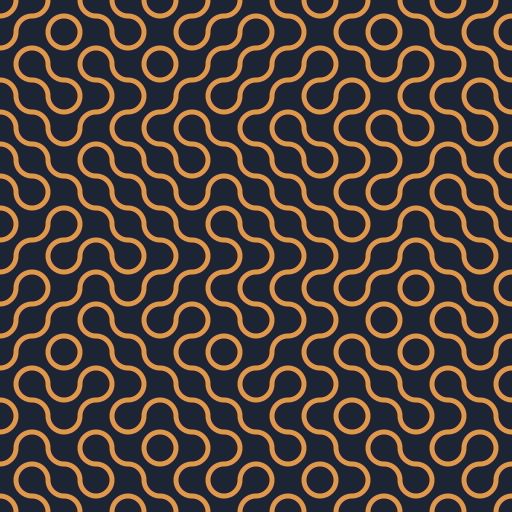

In [2]:
function truchet(seed: number, n = 16, size = 32) {
  const random = rng(seed);
  const paths: string[] = [];
  for (let row = 0; row < n; row++) {
    for (let col = 0; col < n; col++) {
      const x = col * size, y = row * size, h = size / 2;
      paths.push(random() < 0.5
        ? `M${x + h},${y} A${h},${h} 0 0 1 ${x},${y + h} M${x + size},${y + h} A${h},${h} 0 0 0 ${x + h},${y + size}`
        : `M${x + h},${y} A${h},${h} 0 0 0 ${x + size},${y + h} M${x},${y + h} A${h},${h} 0 0 1 ${x + h},${y + size}`);
    }
  }
  const side = n * size;
  return jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="${side}" height="${side}">
    <rect width="${side}" height="${side}" fill="#1d2433"/>
    <path d="${paths.join(" ")}" fill="none" stroke="#e3974a" stroke-width="5" stroke-linecap="round"/>
  </svg>`;
}
truchet(7);

## A flow field

Simplex noise gives smooth randomness: nearby points get similar values.
Read as an angle at each point, it is a field of directions. Thousands of
particles follow it, each leaving a faint line.

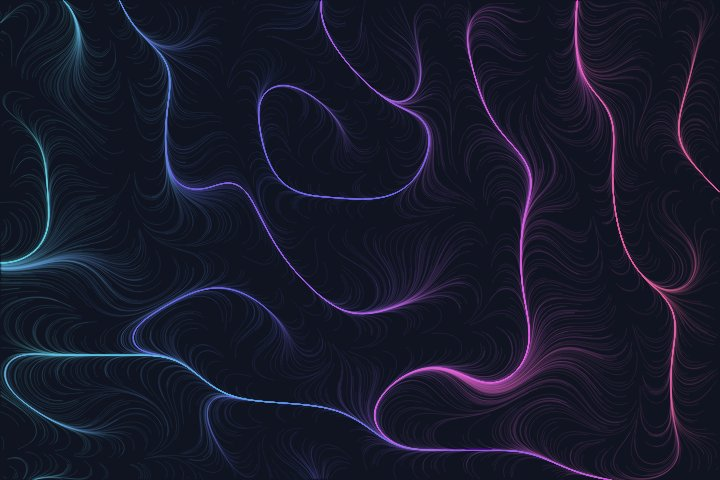

In [3]:
import { createNoise2D } from "npm:simplex-noise@4";

async function flowField(seed: number, { width = 720, height = 480, particles = 3000, steps = 120 } = {}) {
  const random = rng(seed);
  const noise = createNoise2D(random);
  const canvas = makeCanvas(width, height);
  const g = canvas.getContext("2d")!;
  g.fillStyle = "#0f1420";
  g.fillRect(0, 0, width, height);
  g.lineWidth = 0.6;
  for (let i = 0; i < particles; i++) {
    let x = random() * width, y = random() * height;
    const hue = 180 + (x / width) * 160;
    g.strokeStyle = `hsla(${hue}, 70%, 65%, 0.18)`;
    g.beginPath();
    g.moveTo(x, y);
    for (let s = 0; s < steps; s++) {
      const angle = noise(x / 260, y / 260) * Math.PI * 2;
      x += Math.cos(angle) * 2;
      y += Math.sin(angle) * 2;
      if (x < 0 || x > width || y < 0 || y > height) break;
      g.lineTo(x, y);
    }
    g.stroke();
  }
  return show(canvas, "image/jpeg");
}
await flowField(2026);

## Circle packing

Circles grow at random points until they would touch a neighbour. The
cell tries a few thousand points and keeps what fits.

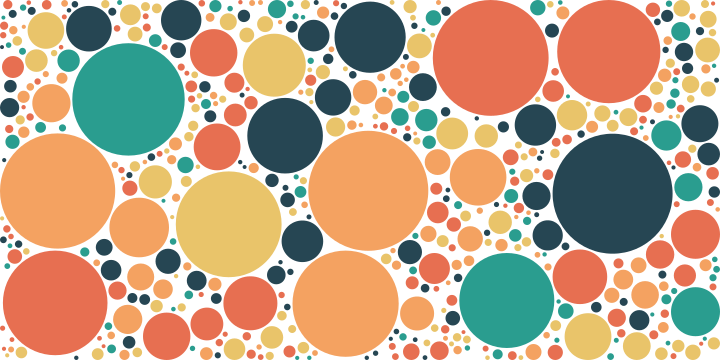

In [4]:
function pack(seed: number, width = 720, height = 360, tries = 6000) {
  const random = rng(seed);
  const circles: { x: number; y: number; r: number }[] = [];
  for (let i = 0; i < tries; i++) {
    const x = random() * width, y = random() * height;
    let r = Math.min(x, y, width - x, height - y, 60);
    for (const c of circles) r = Math.min(r, Math.hypot(c.x - x, c.y - y) - c.r - 2);
    if (r > 2) circles.push({ x, y, r });
  }
  const palette = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"];
  return jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="${width}" height="${height}">
    ${circles.map(c => `<circle cx="${c.x.toFixed(1)}" cy="${c.y.toFixed(1)}" r="${c.r.toFixed(1)}" fill="${palette[Math.floor(random() * palette.length)]}"/>`).join("")}
  </svg>`;
}
pack(11);

## Animation

Updating one output in place, frame by frame, animates it. This harmonograph
traces two decaying pendulums; the saved output is its last frame. Run the
cell to watch it draw, and interrupt the kernel to stop it early.

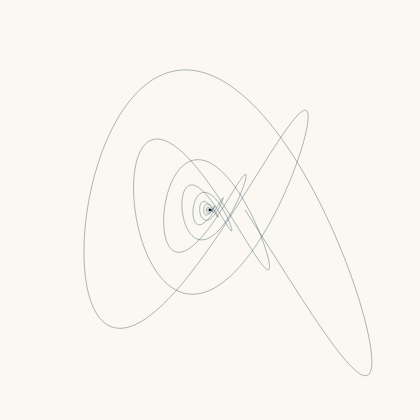

In [5]:
const sleep = (ms: number) => new Promise(resolve => setTimeout(resolve, ms));
const size = 420;
const canvas = makeCanvas(size, size);
const g = canvas.getContext("2d")!;
g.fillStyle = "#fbf8f1";
g.fillRect(0, 0, size, size);
g.strokeStyle = "rgba(38, 70, 83, 0.55)";
g.lineWidth = 0.7;
const f1 = 2.01, f2 = 3, p1 = Math.PI / 16, p2 = 0, decay = 0.0016;
let t = 0;
const point = (t: number) => {
  const d = Math.exp(-decay * t * 100);
  return [
    size / 2 + 180 * d * Math.sin(f1 * t + p1),
    size / 2 + 180 * d * Math.sin(f2 * t + p2) * Math.cos(t / 40),
  ];
};
await jupyter.display(await show(canvas), { display_id: "harmonograph" });
for (let frame = 0; frame < 40; frame++) {
  g.beginPath();
  g.moveTo(...(point(t) as [number, number]));
  for (let i = 0; i < 300; i++) {
    t += 0.02;
    g.lineTo(...(point(t) as [number, number]));
  }
  g.stroke();
  await jupyter.display(await show(canvas), { display_id: "harmonograph", update: true });
  await sleep(50);
}

## Your turn

Change a seed, a palette or a constant and run the cell again. Every
function here takes its seed as an argument, so `truchet(8)` or
`flowField(1)` draws something new.